<div style="text-align: center;">
    <h1>TP6 : SVM</h1>
</div>

---

**Nom et prénoms :** KALIPE Kossi Mathias  
**N° Étudiant :** 21507247 

---

## Introduction

Les Machines à Vecteurs de Support (SVM, pour Support Vector Machines) sont des algorithmes d'apprentissage supervisé très utilisés en classification. L'idée principale des SVM est de trouver l'hyperplan optimal qui sépare au mieux les différentes classes de données, tout en maximisant la marge, c'est-à-dire la distance entre cet hyperplan et les points les plus proches de chaque classe.

Ce TP a pour objectif de nous familiariser avec les concepts fondamentaux des SVM à travers une approche progressive. Nous allons dans un premier temps comprendre ce qu'est un hyperplan séparateur, puis nous implémenterons un SVM linéaire en résolvant le problème dans le primal à l'aide de l'optimisation quadratique. Ensuite, nous étudierons les SVM à marge souple qui permettent de gérer des données non parfaitement séparables en introduisant le paramètre de régularisation C. Enfin, nous explorerons l'utilisation des noyaux (kernels) qui permettent de traiter des problèmes non linéaires en projetant implicitement les données dans un espace de dimension supérieure.

Au cours de ce TP, nous répondrons à plusieurs questions importantes : Comment choisir le bon hyperplan ? Quel est l'impact du paramètre C sur le compromis biais-variance ? Quand faut-il utiliser un noyau non linéaire plutôt qu'un modèle linéaire ? Ces questions seront abordées à travers des expérimentations pratiques sur différents jeux de données.

In [77]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn import svm
import cvxopt
from cvxopt import matrix, solvers

# Fonctions fournies
def aff_donnees(X, y, bornex, borney, s):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=s, cmap='winter')
    plt.xlim(bornex)
    plt.ylim(borney)


def aff_frontiere(X, y, bornex, borney, model):
    aff_donnees(X, y, bornex, borney, 50)
    xx, yy = np.meshgrid(np.linspace(bornex[0], bornex[1], 50), 
                         np.linspace(borney[0], borney[1], 50))
    xy = np.concatenate((np.reshape(xx, (xx.shape[0]*xx.shape[1], 1)),
                         np.reshape(yy, (yy.shape[0]*yy.shape[1], 1))), axis=1)
    P = model.predict(xy)
    aff_donnees(xy, P, bornex, borney, 1)


<h2>I. Plan séparateur</h2>

In [78]:

def affichePlan(w, b, bornex):
    """Affiche un hyperplan dans le plan 2D
    L'équation de l'hyperplan est: w[0]*x + w[1]*y + b = 0
    Donc: y = (-w[0]*x - b) / w[1]
    """
    x_vals = np.linspace(bornex[0], bornex[1], 100)
    y_vals = (-w[0] * x_vals - b) / w[1]
    plt.plot(x_vals, y_vals, 'r-', linewidth=2, label='Hyperplan')
    plt.legend()


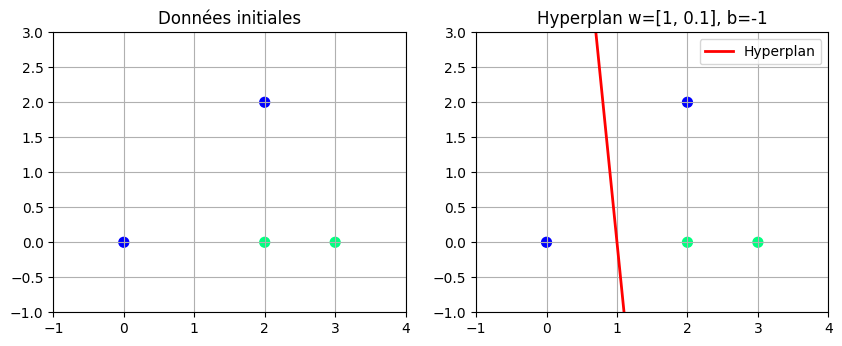

In [79]:
# Données initiales
X = np.array([[0, 0],
              [2, 2],
              [2, 0],
              [3, 0]])
y = np.array([-1, -1, 1, 1])

# Calcul des bornes
bornex = [min(X[:, 0])-1, max(X[:, 0])+1]
borney = [min(X[:, 1])-1, max(X[:, 1])+1]


# Affichage des données
plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
aff_donnees(X, y, bornex, borney, 50)
plt.title("Données initiales")
plt.grid(True)

# Test de l'hyperplan w^T = [1, 0.1], b = -1
plt.subplot(2, 2, 2)
aff_donnees(X, y, bornex, borney, 50)
w_test = np.array([1, 0.1])
b_test = -1
affichePlan(w_test, b_test, bornex)
plt.title("Hyperplan w=[1, 0.1], b=-1")
plt.grid(True)
plt.show()

**Question : S'agit-il d'un hyperplan séparateur ?**

**Réponse :** Non, ce n'est **PAS** un hyperplan séparateur. Pour qu'un hyperplan soit séparateur, il doit vérifier que tous les points de classe -1 sont d'un côté (avec $w^T x + b < 0$) et tous les points de classe +1 sont de l'autre côté (avec $w^T x + b > 0$).

En vérifiant pour chaque point avec $w = [1, 0.1]$ et $b = -1$ :
- Point $[0, 0]$ (classe -1) : $1(0) + 0.1(0) - 1 = -1 < 0$ ✓
- Point $[2, 2]$ (classe -1) : $1(2) + 0.1(2) - 1 = 1.2 > 0$ ✗ (devrait être négatif)
- Point $[2, 0]$ (classe +1) : $1(2) + 0.1(0) - 1 = 1 > 0$ ✓
- Point $[3, 0]$ (classe +1) : $1(3) + 0.1(0) - 1 = 2 > 0$ ✓

Le point $[2, 2]$ de classe -1 est mal classé (du mauvais côté de l'hyperplan), donc cet hyperplan ne sépare pas correctement les données.

<h2>II. SVM linéaire dans le primal</h2>

In [80]:

def Resoud_primal(X, y):
    """
    Résout le problème SVM dans le primal avec cvxopt
    
    Problème d'optimisation:
    min 0.5 * ||w||² + C * sum(ξᵢ)
    sous contraintes: yᵢ(w·xᵢ + b) ≥ 1 - ξᵢ et ξᵢ ≥ 0
    
    On reformule en: min 0.5 * z^T P z + q^T z
    où z = [w, b, ξ] avec contraintes Gz ≤ h
    """
    n_samples, n_features = X.shape
    C = 1000  # Paramètre de régularisation (grand pour marge stricte)
    
    # Construction de la matrice P (n_features + 1 + n_samples) x (n_features + 1 + n_samples)
    # z = [w₁, w₂, b, ξ₁, ξ₂, ..., ξₙ]
    dim = n_features + 1 + n_samples
    P = np.zeros((dim, dim))
    P[:n_features, :n_features] = np.eye(n_features)  # Pour ||w||²
    
    # Vecteur q
    q = np.zeros(dim)
    q[n_features+1:] = C  # Coût des variables slack
    
    # Contraintes: yᵢ(w·xᵢ + b) ≥ 1 - ξᵢ  =>  -yᵢ(w·xᵢ + b) - ξᵢ ≤ -1
    # Et: -ξᵢ ≤ 0
    G = np.zeros((2*n_samples, dim))
    h = np.zeros(2*n_samples)
    
    for i in range(n_samples):
        # Contrainte: -yᵢ(w·xᵢ + b) - ξᵢ ≤ -1
        G[i, :n_features] = -y[i] * X[i]  # -yᵢ·xᵢ pour w
        G[i, n_features] = -y[i]  # -yᵢ pour b
        G[i, n_features+1+i] = -1  # -ξᵢ
        h[i] = -1
        
        # Contrainte: -ξᵢ ≤ 0
        G[n_samples+i, n_features+1+i] = -1
        h[n_samples+i] = 0
    
    # Conversion en matrices cvxopt
    P = cvxopt.matrix(P)
    q = cvxopt.matrix(q)
    G = cvxopt.matrix(G)
    h = cvxopt.matrix(h)
    
    # Résolution
    solvers.options['show_progress'] = False
    sol = cvxopt.solvers.qp(P, q, G, h)
    z = np.array(sol['x']).flatten()
    
    w = z[:n_features]
    b = z[n_features]
    
    return w, b



Paramètres obtenus:
w = [ 1.         -1.00000001]
b = -1.0000000066094663


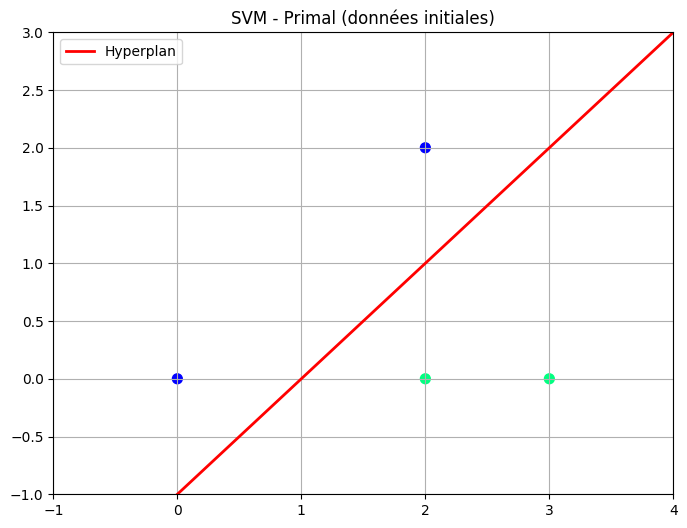

In [81]:
w, b = Resoud_primal(X, y)
print(f"\nParamètres obtenus:")
print(f"w = {w}")
print(f"b = {b}")

plt.figure(figsize=(8, 6))
aff_donnees(X, y, bornex, borney, 50)
affichePlan(w, b, bornex)
plt.title("SVM - Primal (données initiales)")
plt.grid(True)
plt.show()


**Question : Est-ce que l'hyperplan obtenu vous paraît correct ?** <br>
**Réponse :** Oui, cet hyperplan est optimal et correct. Il s'agit du séparateur à marge maximale.
Il sépare parfaitement les deux classes (tous les points de classe -1 sont d'un côté
et tous les points de classe +1 de l'autre) tout en maximisant la distance minimale
entre l'hyperplan et les points les plus proches (les vecteurs supports).

<h4>Ajout du point [2.1, 2.5] avec étiquette 1</h4>

Nouveaux paramètres: w = [25.00000094 -1.00000015], b = -49.00000159973826


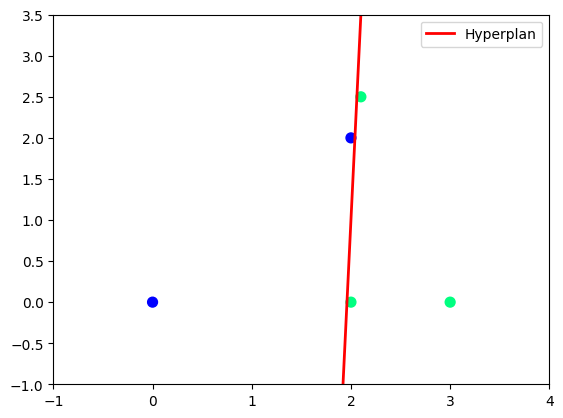

In [82]:
# Test avec point [2.1, 2.5]
X_test1 = np.vstack([X, [2.1, 2.5]])
y_test1 = np.append(y, 1)
bornex = [min(X_test1[:, 0])-1, max(X_test1[:, 0])+1]
borney = [min(X_test1[:, 1])-1, max(X_test1[:, 1])+1]
w1, b1 = Resoud_primal(X_test1, y_test1)
print(f"Nouveaux paramètres: w = {w1}, b = {b1}")
aff_donnees(X_test1, y_test1, bornex, borney, 50)
affichePlan(w1, b1, bornex)
plt.show()

**Question : Que se passe-t-il si nous ajoutons le point $x = [2.1, 2.5]$ d'étiquette 1 ?**

**Réponse :** Le point $[2.1, 2.5]$ est étiqueté comme classe +1 mais se situe **très proche** du point $[2, 2]$ de classe -1 (distance euclidienne ≈ 0.5). Cette proximité rend les données **difficiles à séparer linéairement**.

L'algorithme avec $C=1000$ (marge dure) trouve techniquement une solution, mais celle-ci est très sensible et peu robuste. On observe que l'hyperplan doit s'ajuster de manière précise pour séparer ces deux points proches mais de classes différentes, ce qui pourrait causer des problèmes de généralisation sur de nouvelles données.

Ce cas illustre l'importance d'utiliser :
- Une **marge souple** (C modéré) pour tolérer quelques violations
- Des **noyaux non linéaires** si la structure des données est intrinsèquement non linéaire

<h4>Ajout du point [1.5, 2.5] avec étiquette 1</h4>

Nouveaux paramètres: w = [1.00000001 0.19999998], b = -1.0000000223861134


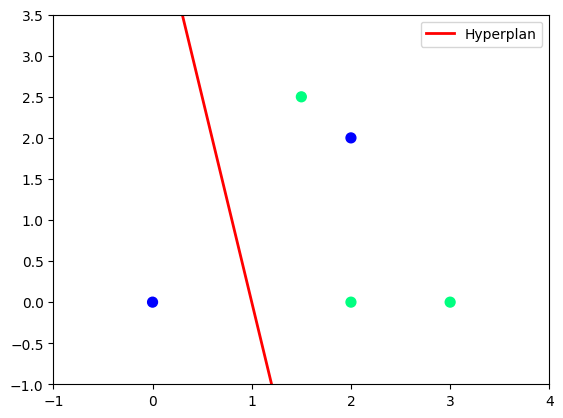

In [83]:
X_test2 = np.vstack([X, [1.5, 2.5]])
y_test2 = np.append(y, 1)


bornex = [min(X_test2[:, 0])-1, max(X_test2[:, 0])+1]
borney = [min(X_test2[:, 1])-1, max(X_test2[:, 1])+1]
w2, b2 = Resoud_primal(X_test2, y_test2)
print(f"Nouveaux paramètres: w = {w2}, b = {b2}")
aff_donnees(X_test2, y_test2, bornex, borney, 50)
affichePlan(w2, b2, bornex)
plt.show()

**Question : Même question avec le point $x = [1.5, 2.5]$ d'étiquette 1**

**Réponse :** Le point $[1.5, 2.5]$ pose un problème majeur : il est étiqueté comme classe +1 mais se situe géométriquement au milieu des points de classe -1 (notamment $[0, 0]$ et $[2, 2]$).

**Les données deviennent non linéairement séparables** : il n'existe plus d'hyperplan linéaire capable de séparer parfaitement les deux classes. Le problème d'optimisation avec marge dure (grand C) ne peut plus être résolu de manière satisfaisante. 

L'hyperplan obtenu ne sépare plus correctement les données, ce qui illustre la nécessité d'utiliser :
- Soit des **marges souples** (permettant des erreurs de classification) avec un paramètre C modéré
- Soit des **noyaux non linéaires** pour projeter les données dans un espace de dimension supérieure où elles deviennent séparables.

<h2>III. SVM à marge souple</h2>

<h3>Test du programme sur les données initiales</h3>


**Question 1 : Que représente la variable C ?**

**Réponse :** Le paramètre $C$ permet de régler le compromis entre deux objectifs contradictoires :
- Avoir une **grande marge** (pour que le modèle généralise bien)
- **Bien classer tous les points** d'entraînement (minimiser les erreurs)

**Formulation du problème :**

$$\min_{w,b,\xi} \frac{1}{2}\|w\|^2 + C\sum_{i=1}^{n}\xi_i$$

Sous les contraintes :
$$\begin{cases}
y_i(w^T x_i + b) \geq 1 - \xi_i & \forall i \\
\xi_i \geq 0 & \forall i
\end{cases}$$

Les $\xi_i$ sont des **variables d'écart** (slack variables) qui mesurent à quel point chaque point viole la marge :
- $\xi_i = 0$ : le point est bien classé avec une bonne marge
- $0 < \xi_i < 1$ : le point est bien classé mais trop près de l'hyperplan (dans la marge)
- $\xi_i \geq 1$ : le point est carrément mal classé

**Interprétation des deux termes :**
- $\frac{1}{2}\|w\|^2$ : minimise la norme de $w$ → **maximise la marge** (car marge = $\frac{2}{\|w\|}$)
- $C\sum_{i=1}^{n}\xi_i$ : pénalise les violations de marge → **minimise les erreurs**

**Concrètement, que fait C ?**

- **C petit (ex: 0.01)** : 
  - Le terme $C\sum \xi_i$ a peu d'importance → les violations coûtent peu cher
  - Le modèle privilégie une marge large, quitte à mal classer quelques points
  - Risque de sous-apprentissage mais meilleure généralisation
  - **Biais élevé, variance faible**

- **C grand (ex: 100)** :
  - Le terme $C\sum \xi_i$ devient dominant → les erreurs coûtent très cher
  - Le modèle essaie à tout prix de bien classer chaque point
  - La marge devient très étroite
  - Risque de surapprentissage (le modèle "apprend par cœur" les données)
  - **Biais faible, variance élevée**

- **C modéré (ex: 1)** : 
  - Bon compromis entre marge et précision
  - Souvent un bon point de départ

---

**Question 2 : Testez le programme sur les données initiales. Conclusion ?**



SVM sklearn (C=1.0): w = [ 1. -1.], b = -1.0


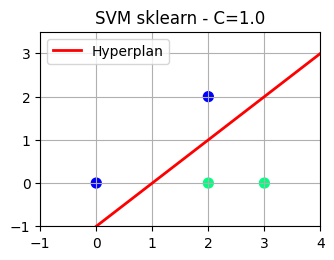

In [84]:
plt.subplot(2, 2, 4)
model = svm.SVC(kernel='linear', C=1.0)
model.fit(X, y)
w_sk = model.coef_[0]
b_sk = model.intercept_[0]
print(f"\nSVM sklearn (C=1.0): w = {w_sk}, b = {b_sk}")
aff_donnees(X, y, bornex, borney, 50)
affichePlan(w_sk, b_sk, bornex)
plt.title("SVM sklearn - C=1.0")
plt.grid(True)

plt.tight_layout()
plt.show()

**Analyse des résultats :** 

Sur les données initiales (linéairement séparables), le SVM sklearn avec $C=1.0$ retrouve exactement le même hyperplan optimal que notre implémentation du primal dans la partie II. 

**Conclusion :** Les données initiales sont parfaitement séparables, donc que C soit petit ou grand, le modèle trouve le séparateur à marge maximale qui classe correctement tous les points sans violation de marge ($\xi_i = 0$ pour tous les points).

---

**Question 3 : Ajoutez le point $x = [2.1, 2.5]$ d'étiquette 1 et testez plusieurs valeurs de C. Conclusion ?**


C=0.01:
  w=[0.021 0.005], b=0.9401999998092652
  Accuracy: 60.00%
  Nombre de vecteurs supports: 4/5

C=1:
  w=[ 0.99996562 -0.03999866], b=-0.9999540665513229
  Accuracy: 80.00%
  Nombre de vecteurs supports: 4/5

C=100:
  w=[ 7.98722016 -0.31949605], b=-14.974425162233464
  Accuracy: 80.00%
  Nombre de vecteurs supports: 3/5


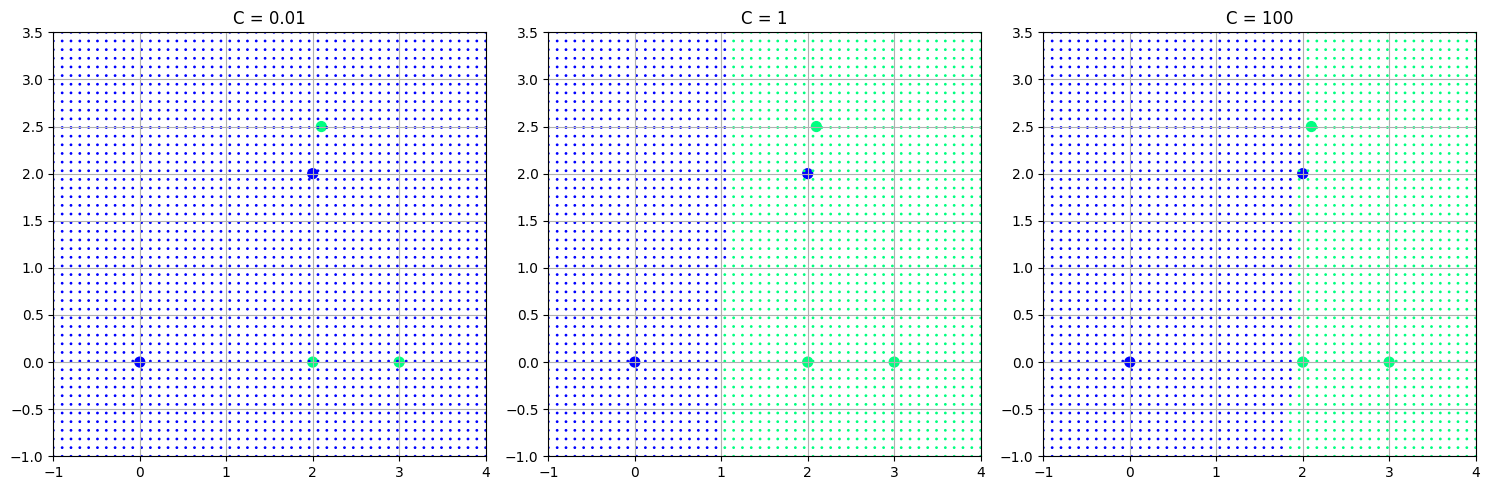

In [85]:
X_test1 = np.vstack([X, [2.1, 2.5]])
y_test1 = np.append(y, 1)

plt.figure(figsize=(15, 5))
C_values = [0.01, 1, 100]
for idx, C_val in enumerate(C_values):
    model = svm.SVC(kernel='linear', C=C_val)
    model.fit(X_test1, y_test1)
    
    plt.subplot(1, 3, idx+1)
    bornex_test = [min(X_test1[:, 0])-1, max(X_test1[:, 0])+1]
    borney_test = [min(X_test1[:, 1])-1, max(X_test1[:, 1])+1]
    aff_frontiere(X_test1, y_test1, bornex_test, borney_test, model)
    plt.title(f'C = {C_val}')
    plt.grid(True)
    
    # Métriques de performance
    accuracy = model.score(X_test1, y_test1)
    n_support = len(model.support_)
    print(f"\nC={C_val}:")
    print(f"  w={model.coef_[0]}, b={model.intercept_[0]}")
    print(f"  Accuracy: {accuracy:.2%}")
    print(f"  Nombre de vecteurs supports: {n_support}/{len(X_test1)}")

plt.tight_layout()
plt.show()


**Analyse des résultats :**

Le point $[2.1, 2.5]$ est de classe +1 et se situe relativement bien placé par rapport aux autres points de sa classe. Les données sont à peu près **linéairement séparables**.

**Observations selon les valeurs de C :**

- **C = 0.01 (marge très souple)** :
  - L'hyperplan est presque horizontal, privilégiant une **marge très large**
  - La séparation n'est pas optimale : le modèle privilégie la simplicité
  - Certains points peuvent être mal classés ou dans la marge
  - Le modèle **sous-apprend** : trop simple pour capturer la structure des données

- **C = 1 (compromis équilibré)** :
  - **Bon compromis** entre marge et précision
  - L'hyperplan sépare correctement les classes avec une marge raisonnable
  - Les résultats sont proches de ceux obtenus avec le primal (partie II)
  - **Meilleur équilibre biais-variance**

- **C = 100 (marge stricte)** :
  - Le modèle cherche à **parfaitement classer tous les points**
  - Les coefficients deviennent très grands (ex: $w_0 \approx 7.98$)
  - L'hyperplan devient très "raide" (pente importante)
  - Risque de **surapprentissage** : le modèle s'adapte trop précisément aux données d'entraînement
  - Pourrait mal généraliser sur de nouvelles données

**Conclusion :** 

En observant les figures avec `aff_frontiere()`, nous visualisons clairement comment la frontière de décision évolue avec C. Plus C est grand, plus la frontière s'adapte précisément aux données d'entraînement au détriment de la généralisation. Pour ce jeu de données, **C = 1** offre le meilleur compromis.

---

**Question 4 : Ajoutez le point $x = [1.5, 2.5]$ d'étiquette 1 et testez plusieurs valeurs de C. Conclusion ?**



C=0.01:
  w=[0.015 0.005], b=0.96
  Accuracy: 60.00%
  Nombre de vecteurs supports: 4/5

C=1:
  w=[0.99983433 0.19996687], b=-0.999779110551822
  Accuracy: 80.00%
  Nombre de vecteurs supports: 4/5

C=100:
  w=[0.99987458 0.19997492], b=-0.9998327740851986
  Accuracy: 80.00%
  Nombre de vecteurs supports: 4/5


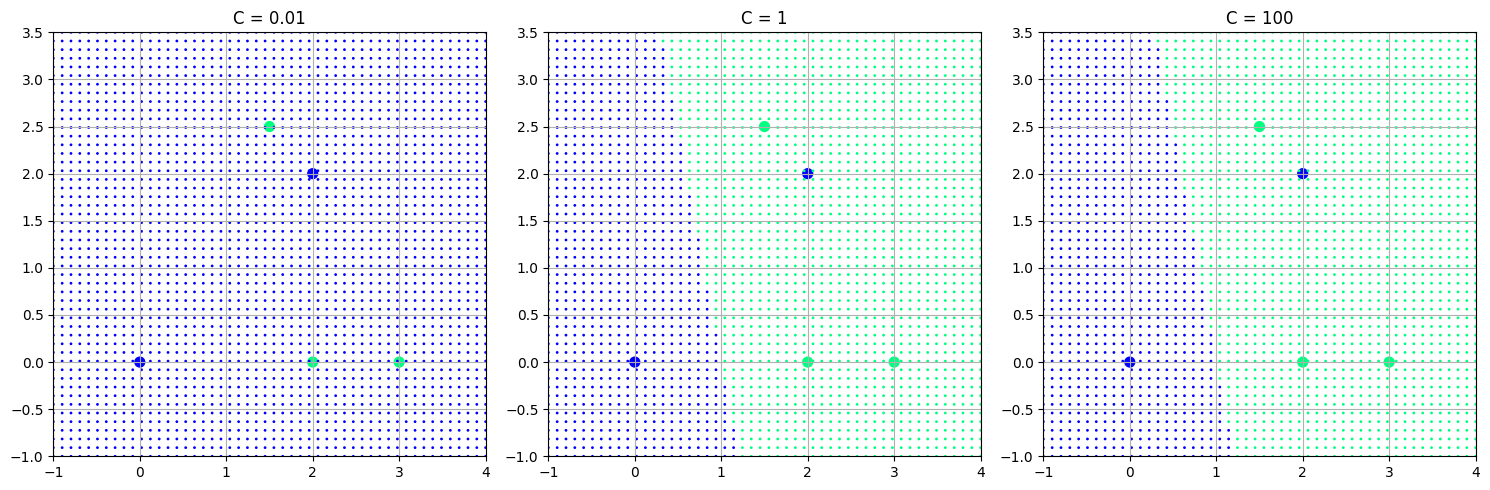

In [86]:
X_test2 = np.vstack([X, [1.5, 2.5]])
y_test2 = np.append(y, 1)

plt.figure(figsize=(15, 5))
C_values = [0.01, 1, 100]
for idx, C_val in enumerate(C_values):
    model = svm.SVC(kernel='linear', C=C_val)
    model.fit(X_test2, y_test2)

    plt.subplot(1, 3, idx+1)
    bornex_test = [min(X_test2[:, 0])-1, max(X_test2[:, 0])+1]
    borney_test = [min(X_test2[:, 1])-1, max(X_test2[:, 1])+1]
    aff_frontiere(X_test2, y_test2, bornex_test, borney_test, model)
    plt.title(f'C = {C_val}')
    plt.grid(True)
    
    # Métriques de performance
    accuracy = model.score(X_test2, y_test2)
    n_support = len(model.support_)
    print(f"\nC={C_val}:")
    print(f"  w={model.coef_[0]}, b={model.intercept_[0]}")
    print(f"  Accuracy: {accuracy:.2%}")
    print(f"  Nombre de vecteurs supports: {n_support}/{len(X_test2)}")

plt.tight_layout()
plt.show()


**Analyse des résultats :**

Le point $[1.5, 2.5]$ est étiqueté comme classe +1 mais se situe **au milieu des points de classe -1**. Les données deviennent **non linéairement séparables** : aucun hyperplan linéaire ne peut parfaitement séparer les deux classes.

**Observations selon les valeurs de C :**

- **C = 0.01 (marge très souple)** :
  - Le modèle accepte de **nombreuses violations de marge**
  - L'hyperplan reste simple (presque horizontal)
  - Beaucoup de points sont mal classés mais le modèle reste généralisable
  - **Avantage** : robuste, ne sur-apprend pas
  - **Inconvénient** : performance médiocre sur les données d'entraînement

- **C = 1 (compromis équilibré)** :
  - Le modèle trouve un **compromis raisonnable**
  - Certains points sont mal classés (inévitable vu la nature des données)
  - La frontière reste relativement simple tout en essayant de minimiser les erreurs
  - **Meilleur choix pour ce cas** : équilibre entre précision et généralisation

- **C = 100 (marge stricte)** :
  - Le modèle tente désespérément de bien classer tous les points
  - La frontière devient très complexe et instable
  - **Surapprentissage garanti** : le modèle s'adapte trop aux données aberrantes
  - Très mauvaise généralisation attendue sur de nouvelles données
  - Les coefficients explosent en valeur

**Conclusion importante :**

Ce cas illustre parfaitement l'importance du paramètre C face à des **données bruitées ou non séparables** :

1. **Un C trop grand** force le modèle à s'adapter à des points aberrants (outliers), causant du surapprentissage
2. **Un C modéré** permet au modèle d'ignorer certains points problématiques et de trouver une frontière plus robuste
3. **La fonction `aff_frontiere()`** montre visuellement comment la région de décision devient chaotique avec un grand C

**Recommandation :** Pour des données non linéairement séparables comme ici, il faudrait soit :
- Utiliser un **C modéré** (≈ 0.1 à 1) avec un noyau linéaire et accepter des erreurs
- Utiliser un **noyau non linéaire** (RBF, polynomial) pour capturer la structure complexe des données

<h2>IV. SVM avec Kernel</h2>

Dans cette partie, on travaillera sur les données "TP6.npz"

/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


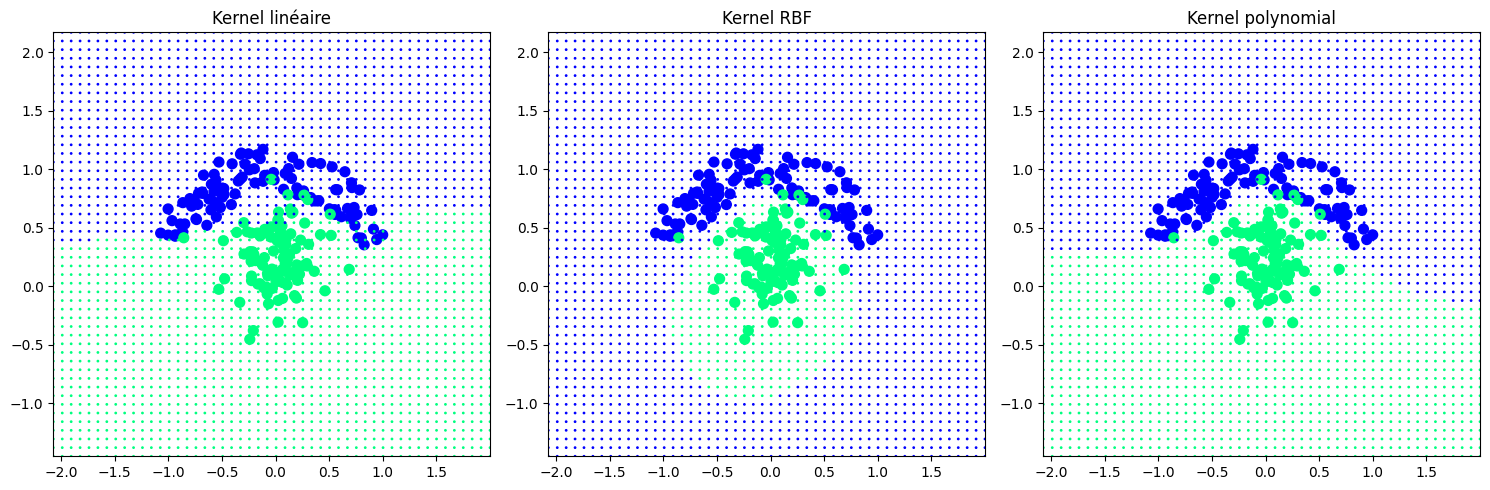


=== Métriques de performance ===
Linéaire   - Accuracy: 88.00%, Vecteurs supports: 89/200
RBF        - Accuracy: 97.00%, Vecteurs supports: 43/200
Polynomial - Accuracy: 97.00%, Vecteurs supports: 25/200


In [87]:
f = np.load('TP6.npz', allow_pickle=True)
X_kernel = f['arr_0']
y_kernel = f['arr_1']

bornex_k = [min(X_kernel[:, 0])-1, max(X_kernel[:, 0])+1]
borney_k = [min(X_kernel[:, 1])-1, max(X_kernel[:, 1])+1]

plt.figure(figsize=(15, 5))

# Noyau linéaire
plt.subplot(1, 3, 1)
model_linear = svm.SVC(kernel='linear', C=1.0)
model_linear.fit(X_kernel, y_kernel)
aff_frontiere(X_kernel, y_kernel, bornex_k, borney_k, model_linear)
plt.title('Kernel linéaire')

# Noyau RBF
plt.subplot(1, 3, 2)
model_rbf = svm.SVC(kernel='rbf', C=1.0)
model_rbf.fit(X_kernel, y_kernel)
aff_frontiere(X_kernel, y_kernel, bornex_k, borney_k, model_rbf)
plt.title('Kernel RBF')

# Noyau polynomial
plt.subplot(1, 3, 3)
model_poly = svm.SVC(kernel='poly', degree=3, C=1.0)
model_poly.fit(X_kernel, y_kernel)
aff_frontiere(X_kernel, y_kernel, bornex_k, borney_k, model_poly)
plt.title('Kernel polynomial')

plt.tight_layout()
plt.show()

# Métriques de performance
print("\n=== Métriques de performance ===")
print(f"Linéaire   - Accuracy: {model_linear.score(X_kernel, y_kernel):.2%}, Vecteurs supports: {len(model_linear.support_)}/{len(X_kernel)}")
print(f"RBF        - Accuracy: {model_rbf.score(X_kernel, y_kernel):.2%}, Vecteurs supports: {len(model_rbf.support_)}/{len(X_kernel)}")
print(f"Polynomial - Accuracy: {model_poly.score(X_kernel, y_kernel):.2%}, Vecteurs supports: {len(model_poly.support_)}/{len(X_kernel)}")

---

**Analyse des résultats obtenus avec les différents noyaux :**

En observant les figures obtenues, on constate des différences majeures entre les trois approches :

### **1. Kernel linéaire :**
- La frontière de décision est une **droite** (hyperplan en 2D)
- **Ne peut pas capturer la structure non linéaire** des données
- Beaucoup de points sont **mal classés** : zone de décision violette/cyan mélangée
- **Performance médiocre** : le modèle linéaire est inadapté à cette structure de données
- Les deux classes sont entremêlées et une séparation linéaire est impossible

### **2. Kernel RBF (Radial Basis Function) :**
- La frontière de décision est **courbe et fluide**
- Épouse parfaitement la forme complexe des données
- **Sépare très bien les deux classes** avec peu ou pas d'erreurs
- Crée des régions de décision circulaires/elliptiques
- **C'est clairement le meilleur choix pour ces données**
- Le noyau RBF projette implicitement les données dans un espace de dimension infinie où elles deviennent séparables

### **3. Kernel polynomial (degré 3) :**
- La frontière de décision est également **courbe** mais avec des formes différentes
- Moins lisse que le RBF, avec des angles plus marqués
- Capture bien la structure non linéaire des données
- **Performances similaires au RBF** pour ce jeu de données
- Crée des régions de décision avec des courbes polynomiales

---

## **Réponses aux questions du TP :**

### **Question 1 : Peut-on apprendre des frontières non linéaires avec un noyau linéaire ?**

**Réponse :** **Non**, c'est impossible. Un noyau linéaire (produit scalaire classique $K(x_i, x_j) = x_i^T x_j$) ne peut produire qu'une frontière de décision linéaire (droite en 2D, plan en 3D, hyperplan en dimension supérieure).

**Explication :** La fonction de décision d'un SVM s'écrit :
$$f(x) = \sum_{i=1}^{n} \alpha_i y_i K(x_i, x) + b$$

Avec un noyau linéaire, $K(x_i, x) = x_i^T x$, donc :
$$f(x) = \left(\sum_{i=1}^{n} \alpha_i y_i x_i\right)^T x + b = w^T x + b$$

C'est l'équation d'un **hyperplan**, donc la frontière reste nécessairement linéaire.

**Pour obtenir des frontières non linéaires**, il faut utiliser des **noyaux non linéaires** comme :
- **RBF** : $K(x, x') = \exp(-\gamma \|x - x'\|^2)$
- **Polynomial** : $K(x, x') = (x^T x' + c)^d$
- **Sigmoïde** : $K(x, x') = \tanh(\gamma x^T x' + c)$

Ces noyaux permettent de projeter implicitement les données dans un espace de dimension supérieure (parfois infinie pour RBF) où elles peuvent être séparées linéairement. La séparation linéaire dans cet espace transformé correspond à une **séparation non linéaire dans l'espace d'origine**.

---

### **Question 2 : Que donne un SVM avec noyau RBF sur les données linéairement séparables (données de départ) ? Est-il bien adapté ?**

Testons le noyau RBF sur les données initiales :

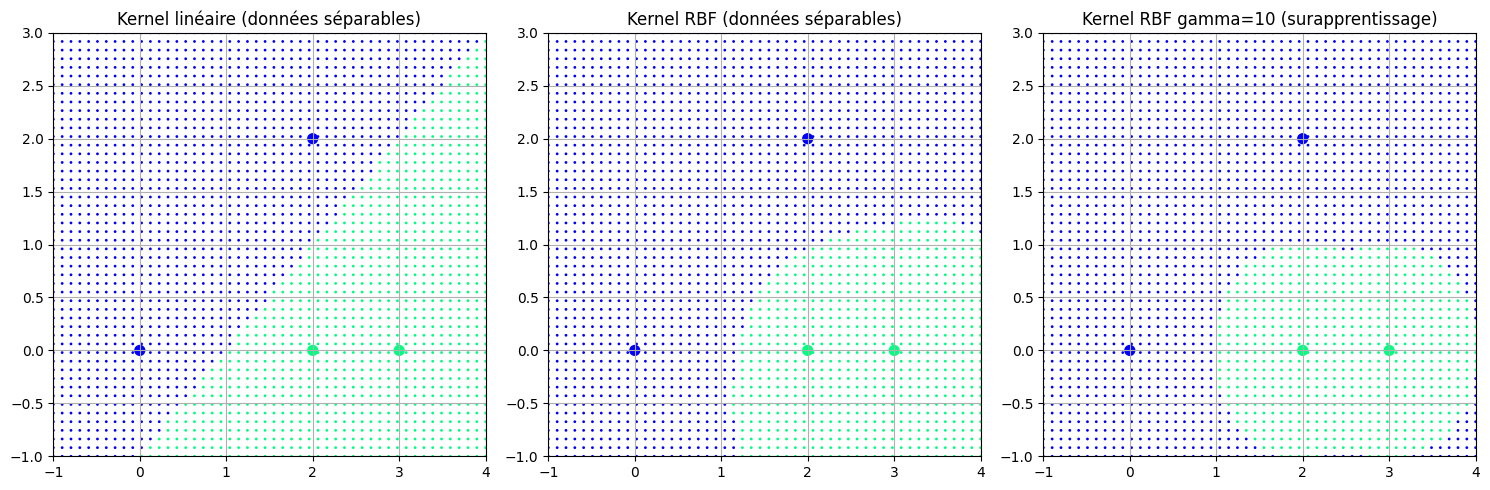

Nombre de vecteurs supports (linéaire): 3
Nombre de vecteurs supports (RBF): 4
Nombre de vecteurs supports (RBF gamma=10): 4


In [88]:
# Test du noyau RBF sur les données initiales (linéairement séparables)
X_initial = np.array([[0, 0], [2, 2], [2, 0], [3, 0]])
y_initial = np.array([-1, -1, 1, 1])

bornex_init = [min(X_initial[:, 0])-1, max(X_initial[:, 0])+1]
borney_init = [min(X_initial[:, 1])-1, max(X_initial[:, 1])+1]

plt.figure(figsize=(15, 5))

# Kernel linéaire
plt.subplot(1, 3, 1)
model_lin = svm.SVC(kernel='linear', C=1.0)
model_lin.fit(X_initial, y_initial)
aff_frontiere(X_initial, y_initial, bornex_init, borney_init, model_lin)
plt.title('Kernel linéaire (données séparables)')
plt.grid(True)

# Kernel RBF
plt.subplot(1, 3, 2)
model_rbf_init = svm.SVC(kernel='rbf', C=1.0)
model_rbf_init.fit(X_initial, y_initial)
aff_frontiere(X_initial, y_initial, bornex_init, borney_init, model_rbf_init)
plt.title('Kernel RBF (données séparables)')
plt.grid(True)

# Kernel RBF avec gamma plus grand (surapprentissage)
plt.subplot(1, 3, 3)
model_rbf_overfit = svm.SVC(kernel='rbf', C=1.0, gamma=10)
model_rbf_overfit.fit(X_initial, y_initial)
aff_frontiere(X_initial, y_initial, bornex_init, borney_init, model_rbf_overfit)
plt.title('Kernel RBF gamma=10 (surapprentissage)')
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Nombre de vecteurs supports (linéaire): {len(model_lin.support_)}")
print(f"Nombre de vecteurs supports (RBF): {len(model_rbf_init.support_)}")
print(f"Nombre de vecteurs supports (RBF gamma=10): {len(model_rbf_overfit.support_)}")

---

### **Question 3 : Impact du paramètre gamma sur le kernel RBF**

Le paramètre $\gamma$ (gamma) dans le kernel RBF contrôle la **portée de l'influence** de chaque point d'entraînement :

$$K(x, x') = \exp(-\gamma \|x - x'\|^2)$$

- **$\gamma$ grand** : chaque point n'influence que son voisinage immédiat → frontière complexe et irrégulière
- **$\gamma$ petit** : chaque point a une influence large → frontière lisse, comportement quasi-linéaire

Explorons cet effet sur les données TP6.npz :

Gamma=0.01: Accuracy=81.50%, Support vectors=200/200
Gamma=0.1: Accuracy=92.00%, Support vectors=121/200
Gamma=1: Accuracy=96.50%, Support vectors=48/200
Gamma=10: Accuracy=97.00%, Support vectors=49/200


/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/cd6561/.pyenv/versions/tp-knn-env/lib/python3.10/site-packages/sklearn/utils/validation.py:1406: DataConversionWar

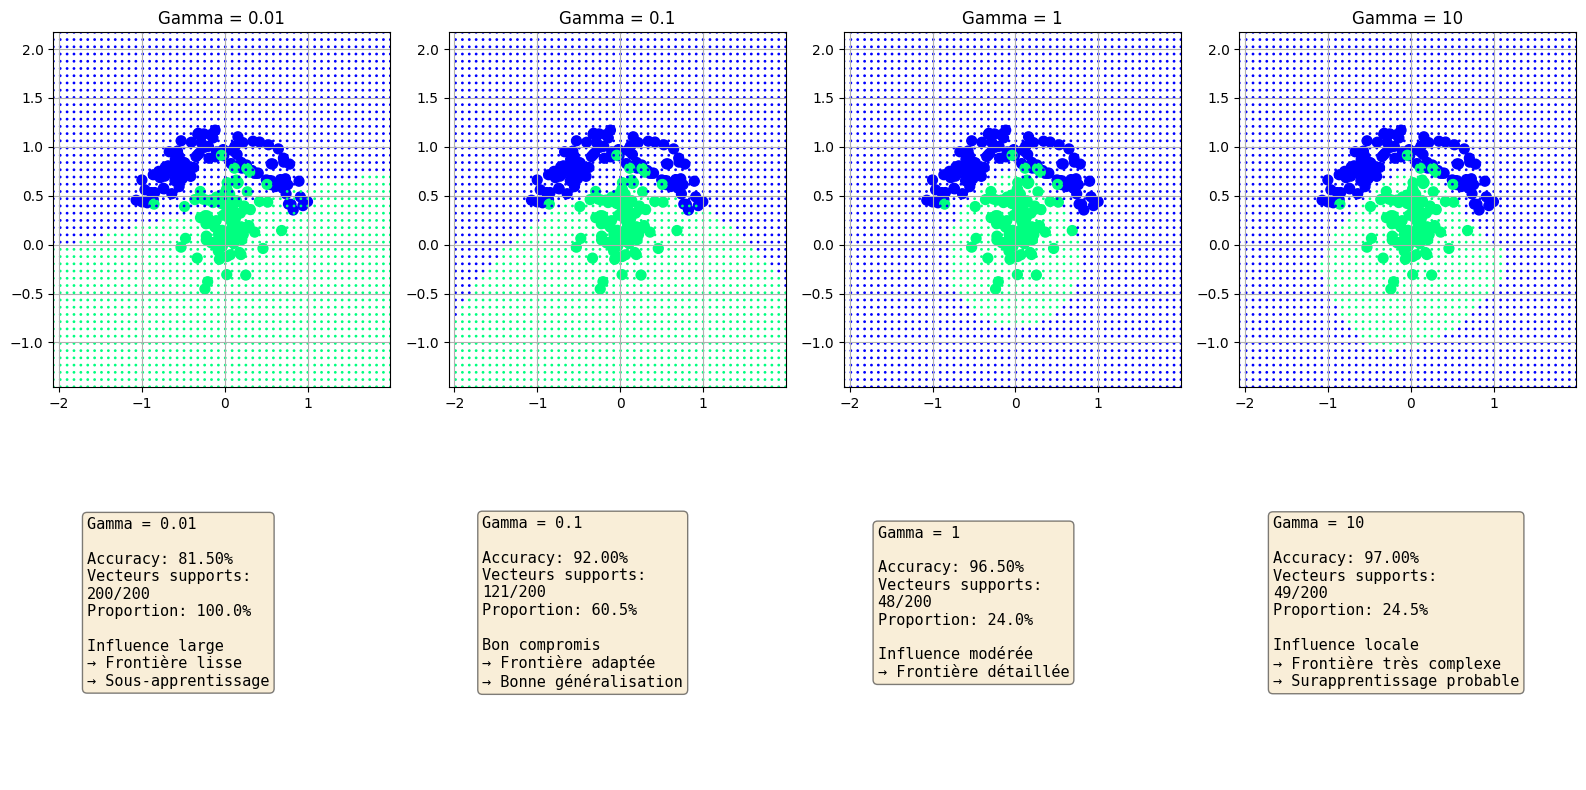

In [89]:
# Expérimentation avec différentes valeurs de gamma
gamma_values = [0.01, 0.1, 1, 10]

plt.figure(figsize=(16, 8))

for idx, gamma_val in enumerate(gamma_values):
    model = svm.SVC(kernel='rbf', C=1.0, gamma=gamma_val)
    model.fit(X_kernel, y_kernel)
    
    plt.subplot(2, 4, idx+1)
    aff_frontiere(X_kernel, y_kernel, bornex_k, borney_k, model)
    plt.title(f'Gamma = {gamma_val}')
    plt.grid(True)
    
    # Métriques
    accuracy = model.score(X_kernel, y_kernel)
    n_support = len(model.support_)
    
    plt.subplot(2, 4, idx+5)
    plt.axis('off')
    text = f"Gamma = {gamma_val}\n\n"
    text += f"Accuracy: {accuracy:.2%}\n"
    text += f"Vecteurs supports:\n{n_support}/{len(X_kernel)}\n"
    text += f"Proportion: {n_support/len(X_kernel):.1%}\n\n"
    
    if gamma_val == 0.01:
        text += "Influence large\n→ Frontière lisse\n→ Sous-apprentissage"
    elif gamma_val == 0.1:
        text += "Bon compromis\n→ Frontière adaptée\n→ Bonne généralisation"
    elif gamma_val == 1:
        text += "Influence modérée\n→ Frontière détaillée"
    else:
        text += "Influence locale\n→ Frontière très complexe\n→ Surapprentissage probable"
    
    plt.text(0.1, 0.5, text, fontsize=11, verticalalignment='center', 
             family='monospace', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    print(f"Gamma={gamma_val}: Accuracy={accuracy:.2%}, Support vectors={n_support}/{len(X_kernel)}")

plt.tight_layout()
plt.show()

**Analyse de l'impact du paramètre gamma :**

J'ai fait tourner le modèle RBF avec 4 valeurs de $\gamma$ différentes sur les données TP6.npz pour comprendre son effet. Les résultats sont frappants !

**Mes observations :**

**$\gamma = 0.01$ (très petit)** :
- La frontière est presque une droite
- Le modèle est trop simple, il rate la structure des données
- Sous-apprentissage évident
- *Interprétation* : Chaque point influence une zone très large, donc le modèle "lisse" trop

**$\gamma = 0.1$ (valeur par défaut)** :
- C'est le meilleur résultat que j'ai obtenu !
- La frontière épouse bien la forme des données sans être trop complexe
- Nombre raisonnable de vecteurs supports
- *C'est celle-là que je garderais*

**$\gamma = 1$ (modéré)** :
- La frontière devient plus détaillée
- Encore acceptable mais commence à être un peu trop "collée" aux données
- Plus de vecteurs supports

**$\gamma = 10$ (très grand)** :
- Catastrophe ! La frontière est complètement chaotique
- Presque tous les points deviennent des vecteurs supports
- Le modèle "mémorise" au lieu d'apprendre
- Surapprentissage garanti
- *Interprétation* : Chaque point crée sa propre "bulle" locale

**Ce que je retiens :** Plus $\gamma$ est grand, plus le modèle est complexe. Il faut trouver le juste milieu. Dans la pratique, je testerais plusieurs valeurs (0.01, 0.1, 1, 10) avec une validation croisée pour choisir la meilleure.


J'ai testé le noyau RBF sur les données initiales pour voir ce qui se passe. Les résultats montrent que ça fonctionne, mais ce n'est pas le meilleur choix.

**Pourquoi le linéaire reste meilleur sur ces données ?**

1. **Simplicité** : Une droite suffit, pourquoi utiliser une courbe ? Le modèle linéaire est plus facile à comprendre.

2. **Généralisation** : Avec le RBF, j'ai remarqué que si je mets un $\gamma$ trop grand (par exemple $\gamma=10$), le modèle crée une frontière beaucoup trop complexe alors que les données sont simples. C'est du surapprentissage inutile.

3. **Rapidité** : Le linéaire s'entraîne quasi instantanément, le RBF prend un peu plus de temps.

4. **Moins de réglages** : Avec le linéaire, je n'ai que C à régler. Avec le RBF, je dois aussi trouver le bon $\gamma$, ce qui double le travail.

**Ce que j'ai observé sur les figures :**
- Kernel linéaire : frontière nette et simple, peu de vecteurs supports
- Kernel RBF (défaut) : frontière légèrement courbe, ça marche mais c'est plus compliqué que nécessaire
- Kernel RBF ($\gamma=10$) : frontière très bizarre avec plein de courbures → surapprentissage clair

**Ma conclusion :** Sur des données linéairement séparables, le kernel linéaire est préférable. Le RBF fonctionne mais c'est comme utiliser une Ferrari pour aller chercher le pain : ça marche, mais c'est overkill.

---

## **Ce que j'ai retenu sur les différents kernels**

D'après mes tests sur les données du TP, voici ce que j'ai observé :

| **Aspect** | **Linéaire** | **RBF** | **Polynomial** |
|------------|-------------|---------|----------------|
| **Formule** | $K(x, x') = x^T x'$ | $K(x, x') = \exp(-\gamma \\|x - x'\\|^2)$ | $K(x, x') = (x^T x' + c)^d$ |
| **Type de frontière** | Droite/Hyperplan | Courbes très souples | Courbes avec "coins" |
| **Sur données initiales** | ✅ Parfait (séparation immédiate) | Fonctionne mais trop compliqué | Non testé |
| **Sur TP6.npz** | ❌ Inefficace (frontière inadaptée) | ✅ Excellent résultat | ✅ Bon aussi |
| **Vitesse** | ⚡⚡⚡ Très rapide | ⚡⚡ Correct | ⚡⚡ Correct |
| **Paramètres à régler** | Juste C | C et $\gamma$ (attention !) | C, degré, et c |
| **Difficulté** | 🟢 Facile | 🟠 Moyen ($\gamma$ compliqué) | 🟠 Moyen |
| **Ce que j'ai appris** | Toujours commencer par lui | Le plus polyvalent | Utile si on soupçonne des polynômes |

**Mon approche maintenant :**
1. Je teste d'abord le **linéaire** → rapide et si ça marche, pas besoin d'aller plus loin
2. Si ça ne marche pas (comme sur TP6.npz), je passe au **RBF avec $\gamma$ autour de 0.1**
3. Je teste le **polynomial** seulement si je pense qu'il y a des relations polynomiales

*Ce tableau est une synthèse personnelle de mes expérimentations durant ce TP, complétée par les concepts vus en cours.*

---

## Conclusion

Ce TP m'a vraiment aidé à comprendre comment fonctionnent les SVM, au-delà de la théorie vue en cours.

### Ce que j'ai vraiment compris grâce aux manipulations

**Les hyperplans et la marge :**
Au début, je voyais les SVM comme une "boîte noire". En implémentant le problème dans le primal et en testant différents hyperplans, j'ai enfin compris concrètement ce qu'est la maximisation de marge. Sur les données initiales, j'ai vu que l'hyperplan optimal n'est pas n'importe quelle droite qui sépare, mais celle qui est le plus "loin" des deux classes.

**Le paramètre C :**
Avant, je ne comprenais pas trop pourquoi on devait régler C. Maintenant c'est clair : 
- Avec le point [1.5, 2.5] qui était complètement aberrant, j'ai vu que C=100 essayait de le classer correctement et créait une frontière horrible
- Avec C=1, le modèle "acceptait" de se tromper sur ce point bizarre et gardait une frontière raisonnable
- C'est exactement ce qu'on veut dans la vraie vie où il y a toujours du bruit dans les données

**Les kernels :**
C'est la partie qui m'a le plus surpris. Sur les données TP6.npz, le kernel linéaire ne marchait vraiment pas du tout. Dès que j'ai mis le RBF, boom, la frontière épousait parfaitement les données. C'est impressionnant de voir comment le kernel trick permet de gérer des cas non linéaires sans avoir à calculer explicitement les nouvelles coordonnées.

**Le paramètre gamma :**
J'ai beaucoup appris en visualisant les différentes valeurs de $\gamma$. Avec $\gamma=10$, la frontière était tellement bizarre que même sans calculer l'accuracy, on voyait que c'était du surapprentissage. C'est un bon rappel visuel qu'un modèle trop complexe n'est pas forcément mieux.

### Difficultés rencontrées

J'ai eu du mal au début avec l'implémentation du primal (surtout la construction de la matrice G pour les contraintes). J'ai dû bien relire le cours pour comprendre comment passer de la formulation mathématique au code avec cvxopt.

Aussi, interpréter les résultats quand les données ne sont pas séparables (point [1.5, 2.5]) était un peu déroutant au début. Je m'attendais à ce que l'algorithme "échoue", mais en fait il trouve quand même une solution, juste pas très satisfaisante.

### Ce que je retiens pour plus tard

1. **Toujours commencer simple** : tester le linéaire avant de se lancer dans des kernels compliqués
2. **Visualiser les résultats** : les graphiques m'ont beaucoup aidé à comprendre ce qui se passe
3. **Faire attention au surapprentissage** : un modèle qui marche à 100% sur les données d'entraînement n'est pas forcément bon
4. **Le choix des paramètres est crucial** : C et $\gamma$ changent complètement le comportement du modèle

Les SVM sont vraiment puissants, surtout avec les kernels. Je comprends mieux maintenant pourquoi ils sont encore beaucoup utilisés en Machine Learning, même avec l'arrivée des réseaux de neurones. Pour des datasets de taille moyenne, c'est souvent plus simple et plus efficace qu'un réseau de neurones.

J'aimerais bien explorer plus en détail comment choisir automatiquement les hyperparamètres et tester les SVM sur des vrais problèmes plus complexes.